In [1]:
'''

Time analysis

By Anita Taylor
'''


'\n\nTime analysis\n\nBy Anita Taylor\n'

In [2]:
'''
Sources:
https://www.kaggle.com/code/prashant111/complete-guide-on-time-series-analysis-in-python/notebook

'''

'\nSources:\nhttps://www.kaggle.com/code/prashant111/complete-guide-on-time-series-analysis-in-python/notebook\n\n'

In [3]:
'''
Notes and questions:

Trend, seasonality, noise

Look for noise: Should I do a lag plot?

Do I have to transform data for granger
'''

'\nNotes and questions:\n\nTrend, seasonality, noise\n\nLook for noise: Should I do a lag plot?\n\nDo I have to transform data for granger\n'

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime 
from sklearn.preprocessing import StandardScaler

#matplotlib inline
#plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

import seaborn as sns

In [2]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype',  'Alkalinity Total 4.5', 'Hardness Total (T)', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology', 'Residue Filterable 1.0u']
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')
Datawithtime = Datat.copy()

#DropDF1c = ['DATE', 'LONGITUDE','LATITUTE', 'year_month','OBSWell']
#Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')


In [3]:
Datat.columns

Index(['OBSWELL', 'LONGITUDE', 'LATITUTE', 'DATE', 'As-T', 'Ca-T', 'Chlrid:D',
       'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance',
       'Sulfat:D', 'pH', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

In [6]:
import pandas as pd

# Convert the 'date' column to datetime
Datat['DATE'] = pd.to_datetime(Datat['DATE'], format='%Y-%m-%d')

# Calculate the mean concentration per date
df_mean = Datat.groupby('DATE')['concentration'].mean().reset_index()

# Create 'year_month' column
Datat['year_month'] = Datat['DATE'].dt.to_period('M')

# Calculate the mean concentration per 'year_month'
df_mean_monthly = Datat.groupby('year_month').mean().reset_index()

KeyError: 'Column not found: concentration'

In [8]:
'''
Scaling

Source:
https://scikit-learn.org/stable/modules/preprocessing.html
https://stats.stackexchange.com/questions/402470/how-can-i-use-scaling-and-log-transforming-together

https://stackoverflow.com/questions/60998512/how-to-scale-all-columns-except-last-column
https://stackoverflow.com/questions/62997793/apply-standarization-to-all-columns-except-one-in-pandas
'''

from sklearn.preprocessing import FunctionTransformer

transformer = FunctionTransformer(np.log1p, validate=True)
dftrans = transformer.transform(df_notypes)

full_data = pd.DataFrame(X_log, columns=['num_col1', 'num_col2', ...]) 
full_data['groups'] = original_data['groups']


NameError: name 'df_notypes' is not defined

In [16]:
'''
Stationary: Dickey Fuller Test

Sources:
https://www.analyticsvidhya.com/blog/2021/06/statistical-tests-to-check-stationarity-in-time-series-part-1/

'''

from statsmodels.tsa.stattools import adfuller
dftestA = adfuller(data1['As-T'],autolag='AIC')
dfoutputA=pd.Series(dftestA[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
for key,value in dftestA[4].items():
    dfoutputA['critical value (%s)'%key]= value
print(dfoutputA)

dftestM = adfuller(data1['Mn-T'],autolag='AIC')
dfoutputM=pd.Series(dftestM[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
for key,value in dftestM[4].items():
    dfoutputM['critical value (%s)'%key]= value
print(dfoutputM)

dftestP = adfuller(data1['Pb-T'],autolag='AIC')
dfoutputP=pd.Series(dftestP[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
for key,value in dftestP[4].items():
    dfoutputP['critical value (%s)'%key]= value
print(dfoutputP)

dftestU = adfuller(data1['U--T'],autolag='AIC')
dfoutputU=pd.Series(dftestU[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
for key,value in dftestU[4].items():
    dfoutputU['critical value (%s)'%key]= value
print(dfoutputU)

NameError: name 'data1' is not defined

In [17]:
'''
KPSS Test

Sources:

'''

def kpss_test(timeseries):
    print ('Results of KPSS Test:')
    kpsstest = kpss(timeseries, regression='c', nlags="auto")
    kpss_output = pd.Series(kpsstest[0:3], index=['Test Statistic','p-value','#Lags Used'])
    for key,value in kpsstest[3].items():
        kpss_output['Critical Value (%s)'%key] = value
    print (kpss_output)
    
kpss_test(df['As-T'])
kpss_test(df['Mn-T'])
kpss_test(df['Pb-T'])
kpss_test(df['U--T'])


NameError: name 'df' is not defined

In [18]:
'''
Autocorrelation

Source:
https://builtin.com/data-science/time-series-python

'''

def autocorr(timeseries):
    autocorrelation_lag1 = timeseries.autocorr(lag=1)
    autocorrelation_lag2 = timeseries.autocorr(lag=3)
    autocorrelation_lag3 = timeseries.autocorr(lag=9)
    print("One Lag: ", autocorrelation_lag1)
    print("Three Lags: ", autocorrelation_lag2)
    print("Nine Lag: ", autocorrelation_lag3)

autocorr(df['As-T'])
autocorr(df['Mn-T'])
autocorr(df['Pb-T'])
autocorr(df['U--T'])
autocorr(df['P--T'])


NameError: name 'df' is not defined

NameError: name 'df' is not defined

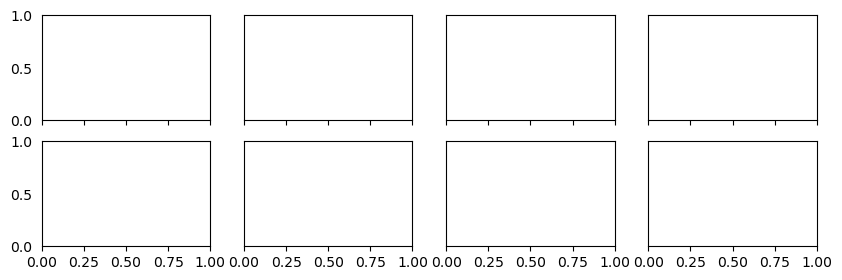

In [19]:
'''
Lag Plot
'''
from pandas.plotting import lag_plot
plt.rcParams.update({'ytick.left' : False, 'axes.titlepad':10})

# Plot
fig, axes = plt.subplots(2, 4, figsize=(10,3), sharex=True, sharey=True, dpi=100)
for i, ax in enumerate(axes.flatten()[:4]):
    lag_plot(df['As-T'], lag=i+1, ax=ax, c='firebrick')
    ax.set_title('Lag ' + str(i+1))
fig.suptitle('As-T', y=1.05)    
for i, ax in enumerate(axes.flatten()[2,:4]):
    lag_plot(df['Mn-T'], lag=i+1, ax=ax, c='firebrick')
    ax.set_title('Lag ' + str(i+1))
fig.suptitle('Mn-T', y=1.05)    


plt.show()


In [21]:
'''
ETS Decomposition

Source:
https://www.kaggle.com/code/prashant111/complete-guide-on-time-series-analysis-in-python/notebook
https://builtin.com/data-science/time-series-python
'''

from statsmodels.tsa.seasonal import seasonal_decompose
from dateutil.parser import parse


def decomp(timeseries):
    adddecompose = seasonal_decompose(timeseries,model='additive', period=10)
    adddecompose = seasonal_decompose(timeseries,model='multiplicative', period=10) 
    plt.rcParams.update({'figure.figsize': (16,12)})
    pyplot.tile(timeseries)
    adddecompose.plot().suptitle('Multiplicative Decomposition', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    adddecompose.plot().suptitle('Additive Decomposition', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    
decomp(df['As-T'])
decomp(df['Mn-T'])
decomp(df['Pb-T'])
decomp(df['U--T'])
decomp(df['P--T'])


NameError: name 'df' is not defined

In [13]:
#Detrending

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.filters.bkfilter import bkfilter
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame

# STL Decomposition for 'As-T'
seasonal = STL(df['As-T']).seasonal 
trenda = STL(df['As-T']).trend
df['As_detrend'] = df['As-T'] - trenda

# Repeat the process for other variables

# Select detrended columns
data = df[['Pb_detrend', 'As_detrend', 'Mn_detrend', 'U_detrend', 'P_detrend']]

# Set up figure and axes using seaborn
g = sns.FacetGrid(data, col="variable", sharex=False, sharey=False, height=3, aspect=1.5)

# Map plot function onto each subplot  
g.map(sns.lineplot, "time", "value")

# Set titles from column names  
g.set_titles(col_template="{col_name}")

# Show the plot
plt.show()


ModuleNotFoundError: No module named 'statsmodels.tsa.filters.bkfilter'

In [14]:
'''
Seasonality:

Source:
'''
from pandas.plotting import autocorrelation_plot

plt.rcParams.update({'figure.figsize':(10,6), 'figure.dpi':120})
autocorrelation_plot(df['U--T'].tolist())

plt.rcParams.update({'figure.figsize':(10,6), 'figure.dpi':120})
autocorrelation_plot(df['As-T'].tolist())

plt.rcParams.update({'figure.figsize':(10,6), 'figure.dpi':120})
autocorrelation_plot(df['Mn-T'].tolist())

plt.rcParams.update({'figure.figsize':(10,6), 'figure.dpi':120})
autocorrelation_plot(df['Pb-T'].tolist())

plt.rcParams.update({'figure.figsize':(10,6), 'figure.dpi':120})
autocorrelation_plot(df['P--T'].tolist())

NameError: name 'df' is not defined

NameError: name 'df' is not defined

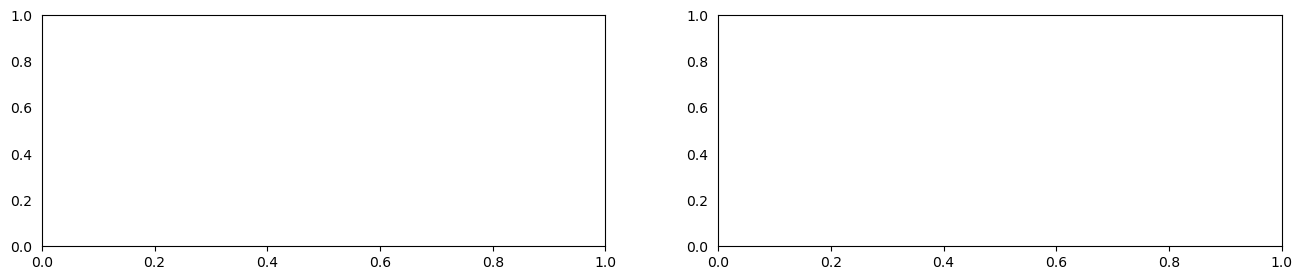

In [15]:
'''
Autocorrelation and partial autocorrelation
'''
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df['As-T'].tolist(), lags=50, ax=axes[0])
plot_pacf(df['As-T'].tolist(), lags=50, ax=axes[1])

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df['Pb-T'].tolist(), lags=50, ax=axes[0])
plot_pacf(df['Pb-T'].tolist(), lags=50, ax=axes[1])

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df['Mn-T'].tolist(), lags=50, ax=axes[0])
plot_pacf(df['Mn-T'].tolist(), lags=50, ax=axes[1])

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df['U--T'].tolist(), lags=50, ax=axes[0])
plot_pacf(df['U--T'].tolist(), lags=50, ax=axes[1])

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df['P--T'].tolist(), lags=50, ax=axes[0])
plot_pacf(df['P--T'].tolist(), lags=50, ax=axes[1])

In [ ]:
'''
Granger causality test 

Source: 
https://www.analyticsvidhya.com/blog/2021/08/granger-causality-in-time-series-explained-using-chicken-and-egg-problem/
'''

from statsmodels.tsa.stattools import grangercausalitytests

grangercausalitytests(df_transformed[['As-T', 'Percp']], maxlag=4)
grangercausalitytests(df_transformed[['As-T', 'Temp']], maxlag=4)
grangercausalitytests(df_transformed[['As-T', 'ChloridD']], maxlag=4)
grangercausalitytests(df_transformed[['As-T', 'Conductivity']], maxlag=4)

grangercausalitytests(df_transformed[['Mn-T', 'Percp']], maxlag=4)
grangercausalitytests(df_transformed[['Mn-T', 'Temp']], maxlag=4)
grangercausalitytests(df_transformed[['Mn-T', 'chloridD']], maxlag=4)
grangercausalitytests(df_transformed[['Mn-T', 'Conductivity']], maxlag=4)

grangercausalitytests(df_transformed[['Pb-T', 'Percp']], maxlag=4)
grangercausalitytests(df_transformed[['Pb-T', 'Temp']], maxlag=4)
grangercausalitytests(df_transformed[['Pb-T', 'chloridD']], maxlag=4)
grangercausalitytests(df_transformed[['Pb-T', 'Conductivity']], maxlag=4)

grangercausalitytests(df_transformed[['U--T', 'Percp']], maxlag=4)
grangercausalitytests(df_transformed[['U--T', 'Temp']], maxlag=4)
grangercausalitytests(df_transformed[['U--T', 'chloridD']], maxlag=4)
grangercausalitytests(df_transformed[['U--T', 'Conductivity']], maxlag=4)

In [ ]:
grangercausalitytests(df_transformed[['P--T', 'Percp']], maxlag=4)
grangercausalitytests(df_transformed[['P--T', 'Temp']], maxlag=4)
grangercausalitytests(df_transformed[['P--T', 'chloridD']], maxlag=4)
grangercausalitytests(df_transformed[['P--T', 'Conductivity']], maxlag=4)

In [8]:
'''
Temporal Correlation matrices

Sources used:
https://medium.com/jovianml/time-series-analysis-data-exploration-and-visualization-9dbede5cbb8d

'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Assuming df is your DataFrame containing time series data

# Extract relevant columns for correlation matrix
columns_of_interest = ['column1', 'column2', 'column3']  # Replace with your actual column names
subset_df = df[columns_of_interest]

# Compute temporal correlation matrix
correlation_matrix = subset_df.corr()

# Plot the correlation matrix
plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Correlation Coefficient')
plt.title('Temporal Correlation Matrix')
plt.xticks(np.arange(len(columns_of_interest)), columns_of_interest, rotation=45)
plt.yticks(np.arange(len(columns_of_interest)), columns_of_interest)
plt.show()


#per time

#Autocorrelation plot

# Partial autocorrelation 

#DIFFERENCE TRANSFORM


'''
Sources used:
https://medium.com/jovianml/time-series-analysis-data-exploration-and-visualization-9dbede5cbb8d

'''

NameError: name 'df' is not defined